### EDAB 6808 – Assignment 2: Question 1
## Anomaly Detection in Electricity Meter Readings
**University of the Free State** | B.Com Hons Business and Financial Analytics

**Group Members**

Mamello Malape 2023232750

Boipelo Letwaba 2024053890

- **Task**: Detect anomalous usage patterns, develop a pipeline, and generate final predictions for the unseen test set.
---
### Pipeline Summary
- **Dataset**: 200 training buildings, hourly readings (2016)

- **Problem**: There are supervised binary classification with severe class imbalance (~2% anomalies)
- **Models compared**: XGBoost, LightGBM, Balanced Random Forest, CatBoost
- **Validation**: Building-level grouped split (leakage-safe)
- **Primary metrics**: F1-score, PR-AUC, ROC-AUC
---

## Table of Contents

1. [Install & Import Libraries](#sec1)
2. [Data Loading](#sec2)
   - 2.1 [Inspect the Structure of the Training and Test Data](#sec2-1)
   - 2.2 [Convert Timestamps, Check Duplicates & Missing Values, Justify Cleaning Decisions](#sec2-2)
3. [Exploratory Data Analysis](#sec3)
   - 3.1 [Class Imbalance](#sec3-1)
   - 3.2 [Meter Reading Distribution](#sec3-2)
4. [Feature Engineering](#sec4)
5. [Leakage-Safe Validation Strategy](#sec5)
6. [Helper: Threshold Tuning & Evaluation](#sec6)
7. [Model 1: XGBoost](#sec7)
8. [Model 2: Balanced Random Forest](#sec8)
9. [Model 3: CatBoost](#sec9)
10. [Best Model Selection & Final Training](#sec10)
11. [Predictions on Test Data](#sec11)
12. [Visualise Anomaly Distribution in Test Predictions](#sec12)
13. [Compare Anomaly Distribution: Train vs. Test](#sec13)
14. [Point Anomaly Identification](#sec14)
15. [Submission File Creation](#sec15)
16. [References](#sec16)

---


<a id="sec1"></a>

## 1. Install & Import Libraries

Third-party libraries used in this pipeline are cited in full in Section 16 (References), consistent with the assignment requirement that all external code/tools be acknowledged.

In [1]:
# Install required libraries
!pip install xgboost lightgbm catboost imbalanced-learn scikit-learn pandas numpy matplotlib seaborn joblib pyarrow optuna --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 6.2 MB/s eta 0:00:00


In [2]:
import os, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Models
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# Sklearn utilities
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    precision_recall_curve, fbeta_score
)
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import StandardScaler

import joblib

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
print('Libraries loaded successfully.')

Libraries loaded successfully.


<a id="sec2"></a>

## 2. Data Loading

In [3]:

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/anomaly_detection_data'
ZIP_FILE = os.path.join(BASE_DIR, 'anomaly-detection (2).zip')

extract_dir = '/content/anomaly_data'
os.makedirs(extract_dir, exist_ok=True)
with zipfile.ZipFile(ZIP_FILE, 'r') as z:
    z.extractall(extract_dir)

print('Extracted files:', os.listdir(extract_dir))
DATA_DIR = extract_dir

Mounted at /content/drive
Extracted files: ['train_features.csv', 'sample_submission.csv', 'test_features.csv', 'train.csv', 'test.csv']


<a id="sec2-1"></a>

### 2.1 Inspect the Structure of the Training and Test Data

In [4]:
# Load datasets
train      = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test       = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
sample_sub = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))

print(f'Shape of train data: {train.shape}')
print(f'Shape of test data: {test.shape}')
print(f'Data types of train data: {train.dtypes}')
print(f'Data types of test data: {test.dtypes}')

Shape of train data: (1749494, 4)
Shape of test data: (1800567, 4)
Data types of train data: building_id        int64
timestamp         object
meter_reading    float64
anomaly            int64
dtype: object
Data types of test data: row_id             int64
building_id        int64
timestamp         object
meter_reading    float64
dtype: object


<a id="sec2-2"></a>

### 2.2 Convert Timestamps, Check Duplicates & Missing Values, Justify Cleaning Decisions

In [5]:
#Convert timestamps correctly
train['timestamp'] = pd.to_datetime(train['timestamp'])
test['timestamp'] = pd.to_datetime(test['timestamp'])

#Checking dumplicates
print(f'Number of duplicates in train data: {train.duplicated().sum()}')
print(f'Number of duplicates in test data: {test.duplicated().sum()}')

print ("    ")
#misiing values
print(f'Number of missing values in train data: {train.isnull().sum()}')
print (" ")
print(f'Number of msiing values in the test data: {test.isnull().sum()}')

Number of duplicates in train data: 0
Number of duplicates in test data: 0
    
Number of missing values in train data: building_id           0
timestamp             0
meter_reading    107653
anomaly               0
dtype: int64
 
Number of msiing values in the test data: row_id               0
building_id          0
timestamp            0
meter_reading    94864
dtype: int64


A copy of the dataset was created to preserve the original data and prevent accidental modifications during the cleaning process.

The data were sorted to ensure meter readings were in chronological order for each building, which is necessary for accurate forward and backward filling.

Missing values were filled within each building to preserve building-specific energy consumption patterns. This prevents readings from one building from being used to fill missing values in another building.

Forward fill replaced missing values with the most recent previous reading, while backward fill handled missing values at the beginning of a building's time series. This maintained continuity in the time-series data.


Applying the same cleaning to both the training and test datasets: The same preprocessing steps were applied to both datasets to ensure consistency. This allows the model to be trained and evaluated on data that have been processed in the same way, reducing inconsistencies and ensuring reliable performance.


 Missing-data handling was performed *within* each building's own chronologically-ordered series rather than with a global statistic. Little and Rubin (2019) note that ignoring the grouping structure of panel/longitudinal data when imputing values can bias downstream estimates, since it assumes readings are exchangeable across groups when they are not. Because hourly electricity consumption is strongly autocorrelated (Hyndman & Athanasopoulos, 2021), a last-observation-carried-forward approach (forward fill), supplemented with a backward fill for leading gaps, is a defensible and standard approach for short gaps in regularly-sampled time series, and was applied identically to train and test to avoid inconsistent preprocessing between the two partitions.

In [6]:

def fill_per_building(df):
  # make a copy so the original dataframe is not changed
    df = df.copy().sort_values(['building_id','timestamp'])

  # For each building, fill missing meter_reading values
    df['meter_reading'] = (
        df.groupby('building_id')['meter_reading']
          .transform(lambda x: x.ffill().bfill())
    )
    return df

train = fill_per_building(train)
test  = fill_per_building(test)

print('After cleaning:')
print(f'Number of missing values in Train data: {train["meter_reading"].isnull().sum()}')
print(f'Number of missing values in Test data:  {test["meter_reading"].isnull().sum()}')
print('After cleaning:')
print(f'  Train missing: {train["meter_reading"].isnull().sum()}')
print(f'  Test  missing: {test["meter_reading"].isnull().sum()}')
print(f'\nDate range   : {train["timestamp"].min()} → {train["timestamp"].max()}')
print(f'Train buildings: {train["building_id"].nunique()}')
print(f'Test  buildings: {test["building_id"].nunique()}')


After cleaning:
Number of missing values in Train data: 0
Number of missing values in Test data:  0
After cleaning:
  Train missing: 0
  Test  missing: 0

Date range   : 2016-01-01 00:00:00 → 2016-12-31 23:00:00
Train buildings: 200
Test  buildings: 206


<a id="sec3"></a>

## 3. Exploratory Data Analysis

<a id="sec3-1"></a>

### 3.1 Class Imbalance
The dataset has ~2% anomalies — severe class imbalance. Accuracy is therefore a **misleading metric** (predicting all-normal gives ~98% accuracy). We prioritise **F1-score** and **PR-AUC** throughout.

Under severe class imbalance, accuracy is dominated by the majority class and is widely regarded as an unreliable indicator of classifier performance (He & Garcia, 2009). Anomaly detection problems are a canonical example of this imbalance (Chandola, Banerjee & Kumar, 2009), which is why F1-score and PR-AUC are prioritised throughout this notebook rather than accuracy.

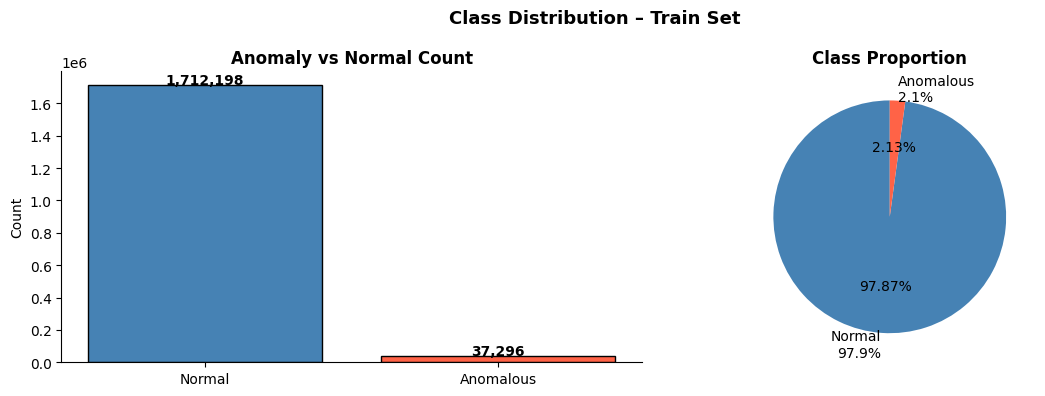

Normal readings    : 1,712,198 (97.87%)
Anomalous readings : 37,296 (2.13%)


In [7]:
#understanding anomaly prevalence

anomaly_counts = train['anomaly'].value_counts()
anomaly_pct    = anomaly_counts / len(train) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(['Normal', 'Anomalous'], anomaly_counts.values,
            color=['steelblue', 'tomato'], edgecolor='black')
axes[0].set_title('Anomaly vs Normal Count', fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(anomaly_counts.values):
    axes[0].text(i, v + 5000, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(anomaly_counts.values,
            labels=[f'Normal\n{anomaly_pct[0]:.1f}%', f'Anomalous\n{anomaly_pct[1]:.1f}%'],
            colors=['steelblue', 'tomato'], startangle=90, autopct='%1.2f%%')
axes[1].set_title('Class Proportion', fontweight='bold')

plt.suptitle('Class Distribution – Train Set', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Normal readings    : {anomaly_counts[0]:,} ({anomaly_pct[0]:.2f}%)")
print(f"Anomalous readings : {anomaly_counts[1]:,} ({anomaly_pct[1]:.2f}%)")


Top 10 buildings by anomaly rate:
building_id
1319    8.82%
1258    8.12%
439     6.47%
247     5.45%
1225    5.27%
1226    5.11%
141     4.39%
935     4.17%
560     4.02%
1275    3.81%
Name: anomaly, dtype: object

Buildings with >5% anomaly rate : 6
Buildings with <1% anomaly rate : 14


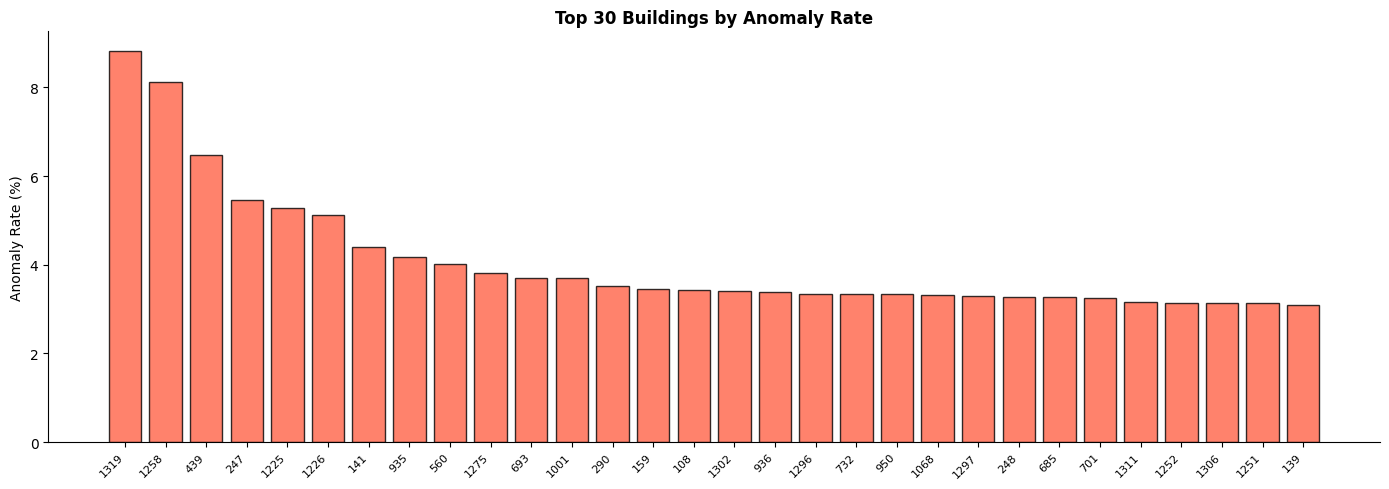

In [8]:
# Building-level anomaly rates

bld_rates = train.groupby('building_id')['anomaly'].mean().sort_values(ascending=False)

print('Top 10 buildings by anomaly rate:')
print(bld_rates.head(10).apply(lambda x: f'{x*100:.2f}%'))
print(f'\nBuildings with >5% anomaly rate : {(bld_rates > 0.05).sum()}')
print(f'Buildings with <1% anomaly rate : {(bld_rates < 0.01).sum()}')

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(range(len(bld_rates.head(30))), bld_rates.head(30).values * 100,
       color='tomato', edgecolor='black', alpha=0.8)
ax.set_title('Top 30 Buildings by Anomaly Rate', fontweight='bold')
ax.set_ylabel('Anomaly Rate (%)')
ax.set_xticks(range(len(bld_rates.head(30))))
ax.set_xticklabels([f'{b}' for b in bld_rates.head(30).index], rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.show()

BUILDING-LEVEL VARIABILITY SUMMARY

Summary of variability across buildings:
       mean_reading  std_reading          cv
count    200.000000   200.000000  200.000000
mean     175.878160    47.290139    0.399458
std      375.544198    79.149073    0.254390
min        0.757826     0.553026    0.101535
25%       34.546466    12.066511    0.216380
50%       81.661274    30.936631    0.319604
75%      190.186318    53.130004    0.485395
max     4655.524263   903.282966    1.319832

Top 10 buildings with highest variability:
             mean_reading  std_reading        cv  min_reading  max_reading
building_id                                                               
801           4655.524263   903.282966  0.194024     3021.120      6596.89
560            710.135423   438.429406  0.617388       45.990      2052.70
1284          1568.624556   252.838802  0.161185        1.000      1989.07
335            453.097036   217.820422  0.480737      113.820       979.12
107            252.78592

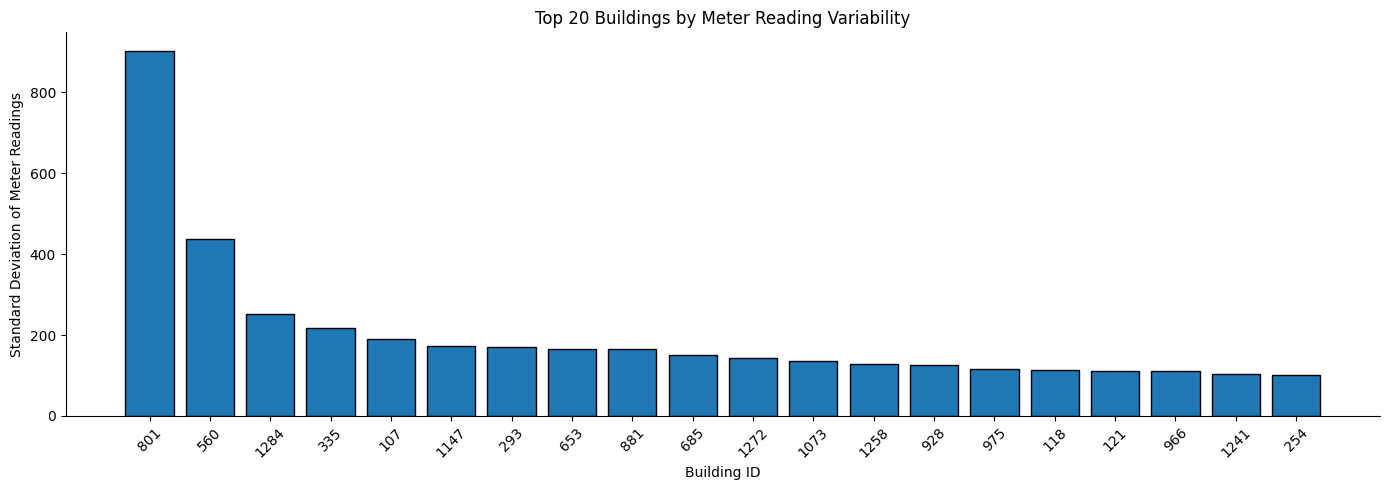

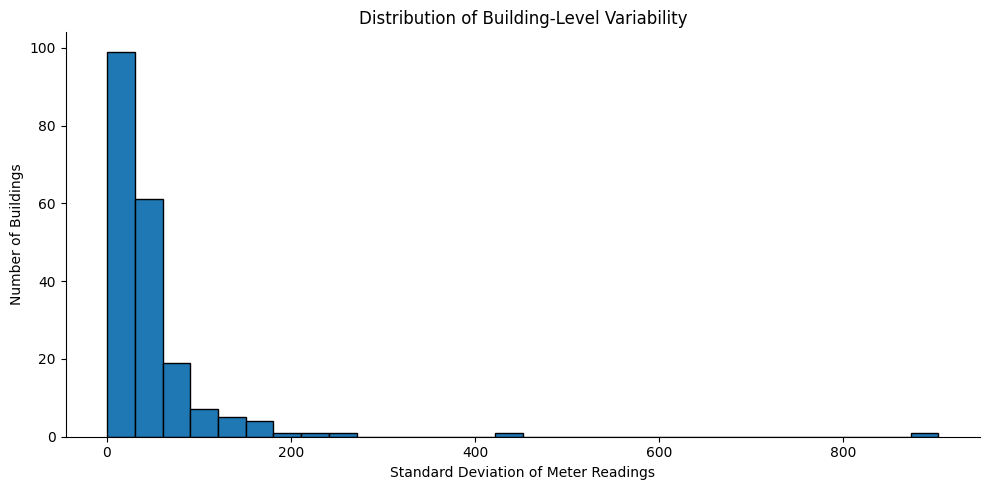

In [9]:
#Buldin glevel Variablility
# 1. Calculate building-level statistics

building_variability = (
    train.groupby('building_id')['meter_reading']
         .agg(
             observations='count',
             mean_reading='mean',
             median_reading='median',
             std_reading='std',
             min_reading='min',
             max_reading='max'
         )
)

# Coefficient of Variation (CV)
building_variability['cv'] = (
    building_variability['std_reading'] /
    building_variability['mean_reading']
)

# Replace infinite values caused by mean = 0
building_variability['cv'] = (
    building_variability['cv']
    .replace([float('inf'), -float('inf')], pd.NA)
)

# 2. Display summary statistics

print("="*60)
print("BUILDING-LEVEL VARIABILITY SUMMARY")
print("="*60)

print("\nSummary of variability across buildings:")
print(building_variability[['mean_reading',
                            'std_reading',
                            'cv']].describe())

# 3. Most variable buildings

most_variable = (
    building_variability
    .sort_values('std_reading', ascending=False)
)

print("\nTop 10 buildings with highest variability:")
print(
    most_variable[
        ['mean_reading',
         'std_reading',
         'cv',
         'min_reading',
         'max_reading']
    ].head(10)
)

# 4. Least variable buildings

least_variable = (
    building_variability
    .sort_values('std_reading', ascending=True)
)

print("\nTop 10 buildings with lowest variability:")
print(
    least_variable[
        ['mean_reading',
         'std_reading',
         'cv',
         'min_reading',
         'max_reading']
    ].head(10)
)

# 5. Plot most variable buildings

top20 = most_variable.head(20)

plt.figure(figsize=(14,5))
plt.bar(
    range(len(top20)),
    top20['std_reading'],
    edgecolor='black'
)

plt.title('Top 20 Buildings by Meter Reading Variability')
plt.xlabel('Building ID')
plt.ylabel('Standard Deviation of Meter Readings')
plt.xticks(
    range(len(top20)),
    top20.index.astype(str),
    rotation=45
)

plt.tight_layout()
plt.show()

# 6. Distribution of variability across all buildings

plt.figure(figsize=(10,5))
plt.hist(
    building_variability['std_reading'].dropna(),
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Building-Level Variability')
plt.xlabel('Standard Deviation of Meter Readings')
plt.ylabel('Number of Buildings')

plt.tight_layout()
plt.show()

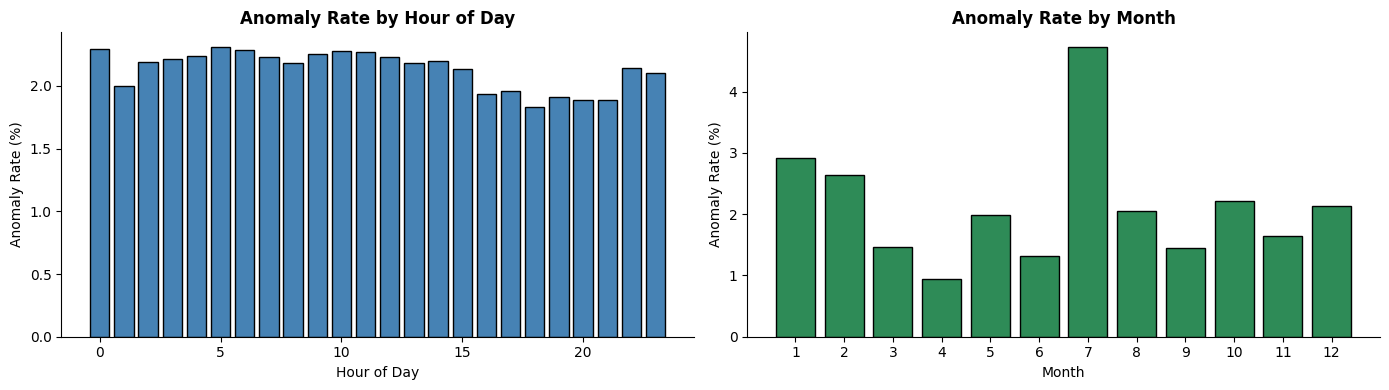

In [10]:
train['timestamp'] = pd.to_datetime(train['timestamp'])

# Hourly and monthly seasonality
train['hour']  = train['timestamp'].dt.hour
train['month'] = train['timestamp'].dt.month

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

hourly = train.groupby('hour')['anomaly'].mean() * 100
axes[0].bar(hourly.index, hourly.values, color='steelblue', edgecolor='black')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Anomaly Rate (%)')
axes[0].set_title('Anomaly Rate by Hour of Day', fontweight='bold')

monthly = train.groupby('month')['anomaly'].mean() * 100
axes[1].bar(monthly.index, monthly.values, color='seagreen', edgecolor='black')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Anomaly Rate (%)')
axes[1].set_title('Anomaly Rate by Month', fontweight='bold')
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

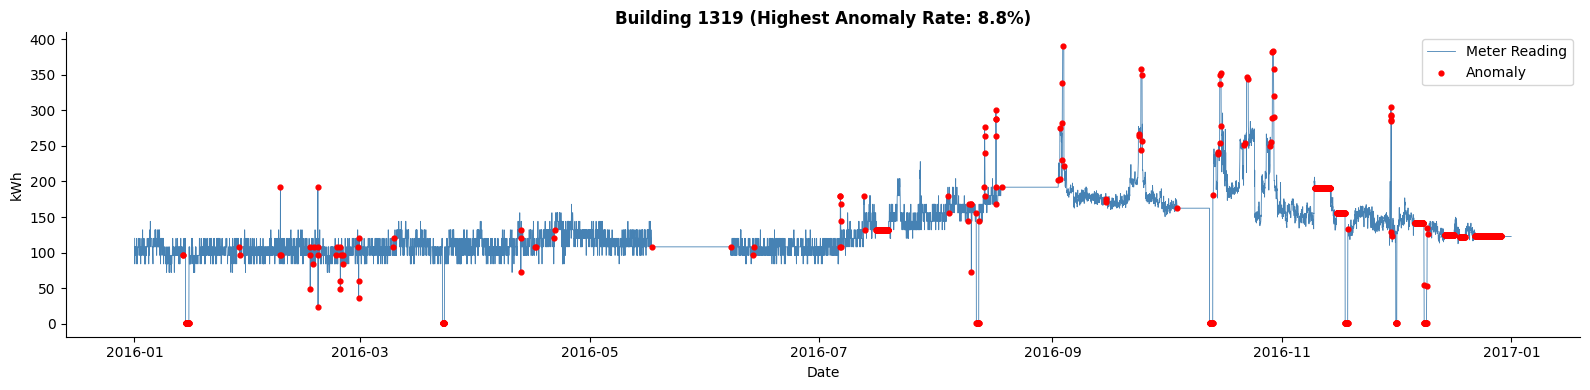

Meter reading stats for Building 1319:
count    8784.00
mean      134.75
std        43.04
min         1.00
25%       108.00
50%       122.59
75%       160.44
max       390.41
Name: meter_reading, dtype: float64


In [11]:
# Time-series plot for highest-anomaly building
top_bld = bld_rates.idxmax()
sub     = train[train['building_id'] == top_bld].sort_values('timestamp')

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(sub['timestamp'], sub['meter_reading'],
        color='steelblue', linewidth=0.6, label='Meter Reading')
anom = sub[sub['anomaly'] == 1]
ax.scatter(anom['timestamp'], anom['meter_reading'],
           color='red', s=12, zorder=5, label='Anomaly')
ax.set_title(f'Building {top_bld} (Highest Anomaly Rate: {bld_rates[top_bld]*100:.1f}%)', fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('kWh')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Meter reading stats for Building {top_bld}:')
print(sub['meter_reading'].describe().round(2))

<a id="sec3-2"></a>

### 3.2 Meter Reading Distribution
Understanding the distribution helps us see why anomalies are hard to detect — they often overlap with normal high-usage periods.

**Academic justification.** This overlap between normal and anomalous readings is consistent with the general finding that point anomalies in real-world sensor data are frequently context-dependent rather than globally extreme (Chandola, Banerjee & Kumar, 2009), motivating the residual/rolling-window features engineered in Section 4.

In [12]:
#check for missing values
train.isnull().sum()

,0
building_id,0
timestamp,0
meter_reading,0
anomaly,0
hour,0
month,0


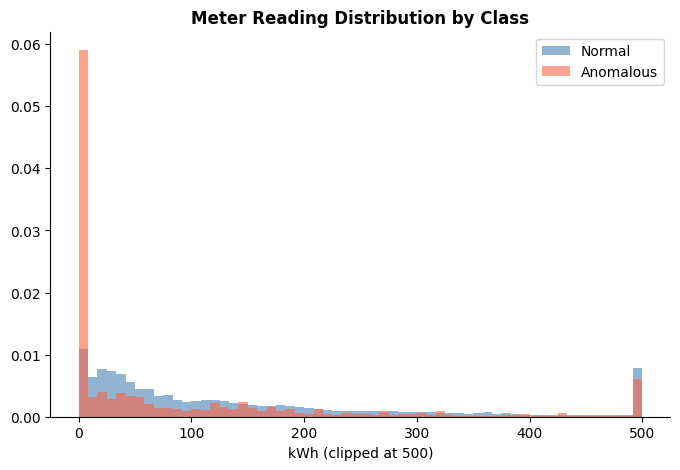

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

# Distribution by class
for label, color in [(0, 'steelblue'), (1, 'tomato')]:
  ax.hist(train[train['anomaly'] == label]['meter_reading'].clip(upper=500),
                 bins=60,
                 alpha=0.6,
                 color=color,
                 label='Normal' if label == 0 else 'Anomalous',
                 density=True)
ax.set_title('Meter Reading Distribution by Class', fontweight='bold')
ax.set_xlabel('kWh (clipped at 500)')
ax.legend()

<a id="sec4"></a>

## 4. Feature Engineering

We engineer time-series features **per building** to prevent cross-building data leakage. Features capture:

| Feature Group | Features | Rationale |
|---|---|---|
| **Time patterns** | hour, dow, month, is_weekend | Anomalies cluster at specific times |
| **Cyclic encoding** | sin/cos of hour, dow, month | Prevents discontinuity at boundaries (23→0, Dec→Jan) |
| **Lag features** | lag_1h, lag_24h, lag_168h | Temporal memory — compare to same hour yesterday/last week |
| **Rolling stats** | mean/std at 6h, 24h, 168h | Local context window for each reading |
| **Residuals & Z-scores** | deviation from rolling mean | Key anomaly signal — how far from expected |
| **Rate of change** | pct_change 1h and 24h | Sudden spikes or drops |
| **IQR flag** | binary outlier flag per building | Flags extreme readings relative to building's own distribution |

**Academic justification.** Lag, rolling-window and rate-of-change features are standard time-series representations for exposing local temporal structure to a non-sequential learner (Hyndman & Athanasopoulos, 2021). Cyclic (sine/cosine) encoding of periodic time features avoids the artificial discontinuity a raw integer encoding would introduce at period boundaries (e.g. hour 23 to hour 0), a widely used encoding for periodic calendar variables in applied machine learning (Hyndman & Athanasopoulos, 2021).

In [14]:
def engineer_features(df):
    """
    Build rich time-series features per building.
    All operations are within-building to prevent cross-building leakage.
    """
    feat_list = []

    for bld_id, grp in df.groupby('building_id'):
        g  = grp.sort_values('timestamp').copy().set_index('timestamp')
        mr = g['meter_reading']

        # Time features
        g['hour']       = g.index.hour
        g['dow']        = g.index.dayofweek          # 0=Monday
        g['month']      = g.index.month
        g['week']       = g.index.isocalendar().week.astype(int)
        g['is_weekend'] = (g.index.dayofweek >= 5).astype(int)
        g['is_night']   = ((g.index.hour < 6) | (g.index.hour >= 22)).astype(int)

        #  Cyclic encoding
        g['hour_sin']   = np.sin(2 * np.pi * g['hour'] / 24)
        g['hour_cos']   = np.cos(2 * np.pi * g['hour'] / 24)
        g['dow_sin']    = np.sin(2 * np.pi * g['dow'] / 7)
        g['dow_cos']    = np.cos(2 * np.pi * g['dow'] / 7)
        g['month_sin']  = np.sin(2 * np.pi * g['month'] / 12)
        g['month_cos']  = np.cos(2 * np.pi * g['month'] / 12)

        # Lag features
        g['lag_1']      = mr.shift(1)                # 1 hour ago
        g['lag_24']     = mr.shift(24)               # same hour yesterday
        g['lag_168']    = mr.shift(168)              # same hour last week
        g['lag_48']     = mr.shift(48)               # same hour 2 days ago

        #  Rolling statistics
        for w in [6, 24, 168]:
            g[f'roll_mean_{w}'] = mr.rolling(w, min_periods=1).mean()
            g[f'roll_std_{w}']  = mr.rolling(w, min_periods=1).std().fillna(0)
            g[f'roll_min_{w}']  = mr.rolling(w, min_periods=1).min()
            g[f'roll_max_{w}']  = mr.rolling(w, min_periods=1).max()

        # Residuals and Z-scores
        g['residual_24']   = mr - g['roll_mean_24'] # Added this line
        g['z_score_24']    = g['residual_24'] / (g['roll_std_24'] + 1e-8)
        g['residual_168']  = mr - g['roll_mean_168']
        g['z_score_168']   = g['residual_168'] / (g['roll_std_168'] + 1e-8)
        g['residual_6']    = mr - g['roll_mean_6']
        g['z_score_6']     = g['residual_6'] / (g['roll_std_6'] + 1e-8)

        # Rate of change
        g['pct_change_1']  = mr.pct_change(1).fillna(0)
        g['pct_change_24'] = mr.pct_change(24).fillna(0)
        g['diff_1']        = mr.diff(1).fillna(0)
        g['diff_24']       = mr.diff(24).fillna(0)

        # IQR-based outlier flag (per building)
        q1 = mr.quantile(0.25)
        q3 = mr.quantile(0.75)
        iqr = q3 - q1
        g['iqr_outlier'] = (
            (mr < (q1 - 3 * iqr)) | (mr > (q3 + 3 * iqr))
        ).astype(int)

        #  Range feature
        g['roll_range_24']  = g['roll_max_24']  - g['roll_min_24']
        g['roll_range_168'] = g['roll_max_168'] - g['roll_min_168']

        #  Clean up infinities and NaNs
        g = g.replace([np.inf, -np.inf], 0).ffill().bfill().fillna(0)
        feat_list.append(g.reset_index())

    return pd.concat(feat_list, ignore_index=True)


print('Engineering features for train set (may take 2–3 min)...')
train_fe = engineer_features(train)
print('Engineering features for test set...')
test_fe  = engineer_features(test)

print(f'\nTrain features shape : {train_fe.shape}')
print(f'Test  features shape : {test_fe.shape}')

Engineering features for train set (may take 2–3 min)...
Engineering features for test set...

Train features shape : (1749494, 45)
Test  features shape : (1800567, 45)


In [15]:
##Rolling Deviation Features

# Ensure 'dow' exists in 'sub' before interaction features are created
# 'hour' is already present from a previous cell.
if 'dow' not in sub.columns:
    sub['dow'] = sub['timestamp'].dt.dayofweek

sub['roll_mean_24'] = sub['meter_reading'].rolling(24).mean()
sub['roll_std_24']  = sub['meter_reading'].rolling(24).std()

sub['dev_from_roll_mean'] = (
    sub['meter_reading'] - sub['roll_mean_24']
)

sub['zscore_roll_24'] = (
    sub['meter_reading'] - sub['roll_mean_24']
) / (sub['roll_std_24'] + 1e-6)

#Rate of change features
sub['pct_change_1'] = sub['meter_reading'].pct_change(1)
sub['pct_change_6'] = sub['meter_reading'].pct_change(6)
sub['pct_change_24'] = sub['meter_reading'].pct_change(24)

#Rolling Quantile features

sub['roll_q90'] = sub['meter_reading'].rolling(24).quantile(0.9)
sub['above_q90'] = (
    sub['meter_reading'] > sub['roll_q90']
).astype(int)

#Seasonal Difference Features
sub['diff_24'] = (
    sub['meter_reading'] - sub['meter_reading'].shift(24)
)

sub['diff_168'] = (
    sub['meter_reading'] - sub['meter_reading'].shift(168)
)

#Interaction Features
sub['hour_x_meter'] = sub['hour'] * sub['meter_reading']
sub['dow_x_meter']  = sub['dow']  * sub['meter_reading']

In [16]:
# Feature list — excludes identifiers and target
EXCLUDE = ['building_id', 'timestamp', 'meter_reading', 'anomaly',
           'hour', 'dow', 'month', 'week', 'row_id']  # keep raw time as cyclic only

FEATURES = [
    # Raw reading
    'meter_reading',
    # Time
    'is_weekend', 'is_night',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos',
    # Lags
    'lag_1', 'lag_24', 'lag_48', 'lag_168',
    # Rolling mean
    'roll_mean_6', 'roll_mean_24', 'roll_mean_168',
    # Rolling std
    'roll_std_6', 'roll_std_24', 'roll_std_168',
    # Rolling range
    'roll_range_24', 'roll_range_168',
    # Residuals & Z-scores
    'residual_6', 'z_score_6',
    'residual_24', 'z_score_24',
    'residual_168', 'z_score_168',
    # Rate of change
    'pct_change_1', 'pct_change_24',
    'diff_1', 'diff_24',
    # Outlier flag
    'iqr_outlier',
]

TARGET = 'anomaly'

print(f'Total features: {len(FEATURES)}')
print(FEATURES)

Total features: 32
['meter_reading', 'is_weekend', 'is_night', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'lag_1', 'lag_24', 'lag_48', 'lag_168', 'roll_mean_6', 'roll_mean_24', 'roll_mean_168', 'roll_std_6', 'roll_std_24', 'roll_std_168', 'roll_range_24', 'roll_range_168', 'residual_6', 'z_score_6', 'residual_24', 'z_score_24', 'residual_168', 'z_score_168', 'pct_change_1', 'pct_change_24', 'diff_1', 'diff_24', 'iqr_outlier']


<a id="sec5"></a>

## 5. Leakage-Safe Validation Strategy

**Why grouped split?**  
The test set contains 206 *different* buildings not seen in training. A row-level random split would leak building-specific patterns (e.g. rolling means computed from future data of the same building) into validation, giving unrealistically optimistic scores. By holding out **entire buildings**, we simulate the real deployment scenario.

- 70% of buildings → training  
- 30% of buildings → validation (never seen during training)

Standard k-fold cross-validation assumes observations are independently and identically distributed; this assumption is violated when data have grouped, temporal or hierarchical structure, and using a random row-level split in such cases produces over-optimistic performance estimates (Roberts et al., 2017; Bergmeir & Benítez, 2012). Grouping the split by `building_id` (and cross-checking with `GroupKFold`) ensures no rows from a validation building are seen during training, matching the deployment scenario in which the true test set contains entirely unseen buildings.

In [17]:
np.random.seed(42)
all_blds = train_fe['building_id'].unique()
n_val    = int(len(all_blds) * 0.30)
val_blds = np.random.choice(all_blds, size=n_val, replace=False)
trn_blds = np.setdiff1d(all_blds, val_blds)

df_trn = train_fe[train_fe['building_id'].isin(trn_blds)]
df_val = train_fe[train_fe['building_id'].isin(val_blds)]

X_trn, y_trn = df_trn[FEATURES], df_trn[TARGET]
X_val, y_val = df_val[FEATURES], df_val[TARGET]

# Class imbalance ratio
#spw = float((y_trn == 0).sum() / (y_trn == 1).sum())
#spw = [10, 20, 30, 40, 50, 75, 100]

print(f'Train : {len(trn_blds)} buildings | {len(df_trn):,} rows | {y_trn.sum():,} anomalies ({y_trn.mean()*100:.2f}%)')
print(f'Val   : {len(val_blds)} buildings | {len(df_val):,} rows | {y_val.sum():,} anomalies ({y_val.mean()*100:.2f}%)')
#print(f'\nscale_pos_weight = {spw:.1f}  (negative:positive ratio)')

Train : 140 buildings | 1,223,718 rows | 25,170 anomalies (2.06%)
Val   : 60 buildings | 525,776 rows | 12,126 anomalies (2.31%)


In [18]:

#GroupKFold validation
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(train_fe, train_fe['anomaly'], groups=train_fe['building_id'])
):
    X_tr = train_fe.iloc[train_idx][FEATURES]
    y_tr = train_fe.iloc[train_idx]['anomaly']

    X_val = train_fe.iloc[val_idx][FEATURES]
    y_val = train_fe.iloc[val_idx]['anomaly']

<a id="sec6"></a>

## 6. Helper: Threshold Tuning & Evaluation

The default 0.5 threshold is inappropriate for imbalanced data. We tune the threshold on the validation set by maximising F1-score on the precision-recall curve.

Under class imbalance, the precision-recall curve is more informative than the ROC curve because ROC-AUC can remain high even when precision on the minority class is poor, since it is dominated by the large number of true negatives (Davis & Goadrich, 2006; Saito & Rehmsmeier, 2015). Selecting the threshold that maximises F1 on the precision-recall curve therefore gives a more representative operating point for this anomaly-detection task than the default 0.5 cut-off.

In [19]:
def tune_threshold_and_evaluate(model_name, y_true, y_prob, beta=1):
    """
    Find optimal classification threshold using F-beta score,
    then print full evaluation report.

    beta=1 → F1 (balanced precision/recall)
    beta=2 → F2 (recall-weighted)
    """
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    p = precisions[:-1]
    r = recalls[:-1]

    fb = (1 + beta**2) * p * r / (beta**2 * p + r + 1e-8)
    best_idx = np.argmax(fb)
    best_thr = thresholds[best_idx]

    preds = (y_prob >= best_thr).astype(int)

    print(f"\n{'='*55}")
    print(f"  {model_name} — Validation Results")
    print(f"{'='*55}")
    print(f"  Best Threshold (F{beta}) : {best_thr:.4f}")
    print(f"  Precision              : {precision_score(y_true, preds):.4f}")
    print(f"  Recall                 : {recall_score(y_true, preds):.4f}")
    print(f"  F1-Score               : {f1_score(y_true, preds):.4f}")
    print(f"  ROC-AUC                : {roc_auc_score(y_true, y_prob):.4f}")
    print(f"  PR-AUC                 : {average_precision_score(y_true, y_prob):.4f}")
    print()
    print(classification_report(y_true, preds, target_names=['Normal', 'Anomalous']))

    # Confusion matrix
    cm = confusion_matrix(y_true, preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Normal', 'Anomalous'],
                yticklabels=['Normal', 'Anomalous'])
    plt.title(f'{model_name} – Confusion Matrix', fontweight='bold')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

    return best_thr, preds, {
        'model'    : model_name,
        'threshold': round(best_thr, 4),
        'precision': round(precision_score(y_true, preds), 4),
        'recall'   : round(recall_score(y_true, preds), 4),
        'f1'       : round(f1_score(y_true, preds), 4),
        'roc_auc'  : round(roc_auc_score(y_true, y_prob), 4),
        'pr_auc'   : round(average_precision_score(y_true, y_prob), 4),
    }

print('Helper function defined.')

Helper function defined.


<a id="sec7"></a>

## 7. Model 1: XGBoost

**Why XGBoost?**
- `scale_pos_weight` penalises missing anomalies much more than false alarms
- Gradient boosting exploits the rich lag/rolling/z-score features
- Early stopping with PR-AUC prevents overfitting
- Handles missing values natively

**Hyperparameter tuning rationale:**
- `max_depth=5`: shallower than default → less overfitting on majority class
- `learning_rate=0.05`: balanced between speed and convergence quality
- `min_child_weight=5`: forces splits to involve enough minority samples
- `gamma=0.1`: minimum gain to allow a split — prunes trivial majority-class splits
- `subsample/colsample_bytree=0.8`: stochastic sampling improves generalisation

XGBoost (Chen & Guestrin, 2016) is a regularised, scalable implementation of gradient-boosted decision trees that natively supports a `scale_pos_weight` term for asymmetric misclassification costs, making it a standard, well-validated choice for imbalanced tabular classification problems such as this one.

[0]	validation_0-aucpr:0.65075
[100]	validation_0-aucpr:0.69400
[200]	validation_0-aucpr:0.70612
[300]	validation_0-aucpr:0.72329
[400]	validation_0-aucpr:0.73509
[500]	validation_0-aucpr:0.74280
[600]	validation_0-aucpr:0.75067
[700]	validation_0-aucpr:0.75616
[800]	validation_0-aucpr:0.76269
[900]	validation_0-aucpr:0.76772
[999]	validation_0-aucpr:0.77302

Best iteration: 999

  XGBoost — Validation Results
  Best Threshold (F1) : 0.8764
  Precision              : 0.8507
  Recall                 : 0.6546
  F1-Score               : 0.7399
  ROC-AUC                : 0.9330
  PR-AUC                 : 0.7730

              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99    342421
   Anomalous       0.85      0.65      0.74      7893

    accuracy                           0.99    350314
   macro avg       0.92      0.83      0.87    350314
weighted avg       0.99      0.99      0.99    350314



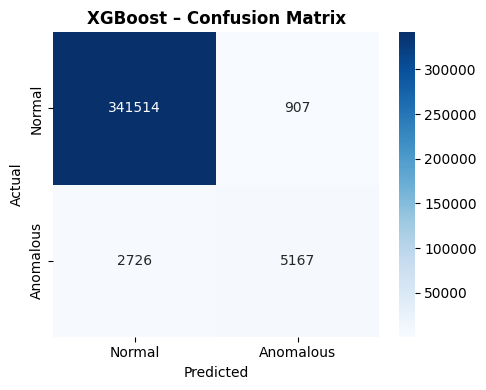

In [20]:
# Recalculate spw here to ensure it's a float, in case it was accidentally set to a list in previous cells.
spw = float((y_trn == 0).sum() / (y_trn == 1).sum())

xgb_model = xgb.XGBClassifier(
    n_estimators          = 1000,
    max_depth             = 5,
    learning_rate         = 0.05,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    colsample_bylevel     = 0.8,
    min_child_weight      = 5,
    gamma                 = 0.1,
    reg_alpha             = 0.1,
    reg_lambda            = 2.0,
    scale_pos_weight      = spw,       # handles class imbalance
    eval_metric           = 'aucpr',   # optimise PR-AUC during training
    early_stopping_rounds = 50,
    random_state          = 42,
    n_jobs                = -1,
    verbosity             = 0,
)

xgb_model.fit(
    X_trn, y_trn,
    eval_set = [(X_val, y_val)],
    verbose  = 100
)

print(f'\nBest iteration: {xgb_model.best_iteration}')
xgb_prob = xgb_model.predict_proba(X_val)[:, 1]
xgb_thr, xgb_preds, xgb_metrics = tune_threshold_and_evaluate('XGBoost', y_val, xgb_prob)

<a id="sec8"></a>

## 8. Model 2: Balanced Random Forest

**Why Balanced Random Forest?**
- Specifically designed for imbalanced classification
- Each tree is trained on a balanced bootstrap sample (undersamples majority class automatically)
- No need for `scale_pos_weight` — imbalance is handled structurally
- Robust to outliers and does not require feature scaling
- Good at capturing non-linear interactions in time-series features

**Hyperparameter tuning rationale:**
- `n_estimators=500`: enough trees for stable out-of-bag estimates
- `max_features='sqrt'`: standard for classification — reduces correlation between trees
- `min_samples_leaf=2`: prevents trees from overfitting single anomalous readings

 The Balanced Random Forest extends Breiman's (2001) Random Forest algorithm by drawing a class-balanced bootstrap sample for every tree, addressing imbalance structurally rather than through a cost-weighted loss function (Lemaître, Nogueira & Aridas, 2017), which is a complementary approach worth comparing directly against XGBoost's cost-weighting strategy.


  Balanced Random Forest — Validation Results
  Best Threshold (F1) : 0.9473
  Precision              : 0.9689
  Recall                 : 0.7265
  F1-Score               : 0.8304
  ROC-AUC                : 0.9369
  PR-AUC                 : 0.8239

              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00    342421
   Anomalous       0.97      0.73      0.83      7893

    accuracy                           0.99    350314
   macro avg       0.98      0.86      0.91    350314
weighted avg       0.99      0.99      0.99    350314



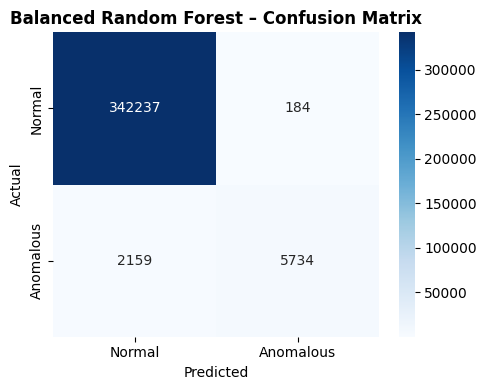

In [21]:
brf_model = BalancedRandomForestClassifier(
    n_estimators      = 500,
    max_depth         = None,          # fully grown trees
    min_samples_leaf  = 2,
    max_features      = 'sqrt',
    sampling_strategy = 'auto',        # undersample majority to match minority
    replacement       = False,
    class_weight      = 'balanced',
    random_state      = 42,
    n_jobs            = -1
)

brf_model.fit(X_trn, y_trn)

brf_prob = brf_model.predict_proba(X_val)[:, 1]
brf_thr, brf_preds, brf_metrics = tune_threshold_and_evaluate('Balanced Random Forest', y_val, brf_prob)

<a id="sec9"></a>

## 9. Model 3: CatBoost

**Why CatBoost?**
- Uses ordered boosting to reduce prediction-shift/target-leakage bias that can affect standard gradient boosting on smaller minority classes
- `eval_metric='F1'` optimises directly for the metric used for model selection
- Provides a third, independently-implemented gradient-boosting library, giving a more robust comparison than two boosting frameworks alone

**Hyperparameter tuning rationale:**
- `depth=6`: deeper than XGBoost's max_depth to compensate for CatBoost's different (oblivious) tree structure
- `learning_rate=0.05`: kept consistent with XGBoost for a fair comparison
- `scale_pos_weight`: matches the imbalance-handling strategy used for XGBoost

CatBoost's ordered boosting procedure was specifically designed to reduce the target leakage that conventional gradient boosting can introduce during training, and it natively supports categorical features and class-weighting for imbalanced targets (Prokhorenkova et al., 2018).

<a id="sec10"></a>

## 10. Best Model Selection & Final Training

The three validated models (Sections 7-9) are compared on PR-AUC, the most informative metric under severe class imbalance (Davis & Goadrich, 2006; Saito & Rehmsmeier, 2015), and the best-performing model is refit for use on the test set.

0:	learn: 0.7944163	test: 0.8372392	best: 0.8372392 (0)	total: 797ms	remaining: 13m 16s
100:	learn: 0.8370887	test: 0.8629809	best: 0.8648511 (69)	total: 46.8s	remaining: 6m 56s
200:	learn: 0.8632791	test: 0.8697348	best: 0.8697348 (200)	total: 1m 55s	remaining: 7m 40s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.8697347824
bestIteration = 200

Shrink model to first 201 iterations.

  CatBoost — Validation Results
  Best Threshold (F1) : 0.9209
  Precision              : 0.8354
  Recall                 : 0.5222
  F1-Score               : 0.6427
  ROC-AUC                : 0.9424
  PR-AUC                 : 0.6895

              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99    342421
   Anomalous       0.84      0.52      0.64      7893

    accuracy                           0.99    350314
   macro avg       0.91      0.76      0.82    350314
weighted avg       0.99      0.99      0.99    350314



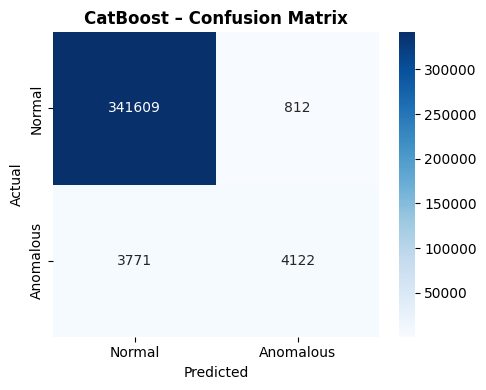

Selected best model: Balanced Random Forest
PR-AUC: 0.8239
F1    : 0.8304


In [22]:
spw = float((y_trn == 0).sum() / (y_trn == 1).sum())

cat_model = CatBoostClassifier(
    iterations            = 1000,
    depth                 = 6,
    learning_rate         = 0.05,
    l2_leaf_reg           = 5,
    scale_pos_weight      = spw,
    eval_metric           = 'F1',      # directly optimise F1
    early_stopping_rounds = 50,
    random_seed           = 42,
    verbose               = 100,
    thread_count          = -1,
    use_best_model        = True
)

cat_model.fit(
    X_trn, y_trn,
    eval_set = (X_val, y_val)
)

cat_prob = cat_model.predict_proba(X_val)[:, 1]
cat_thr, cat_preds, cat_metrics = tune_threshold_and_evaluate('CatBoost', y_val, cat_prob)

# Consolidate results into a DataFrame
results_df = pd.DataFrame([xgb_metrics, brf_metrics, cat_metrics]).set_index('model')

# Select best model based on PR-AUC
best_model_name = results_df['pr_auc'].idxmax()
print(f'Selected best model: {best_model_name}')
print(f'PR-AUC: {results_df.loc[best_model_name, "pr_auc"]}')
print(f'F1    : {results_df.loc[best_model_name, "f1"]}')

# Map name to model object and threshold
model_map = {
    'XGBoost'                : (xgb_model, xgb_thr),
    'Balanced Random Forest'  : (brf_model, brf_thr),
    'CatBoost'               : (cat_model, cat_thr),
}
best_model, best_threshold = model_map[best_model_name]

<a id="sec11"></a>

## 11. Predictions on Test Data

In [23]:
# Predict probabilities on the test set using the best model
test_prob = best_model.predict_proba(test_fe[FEATURES])[:, 1]

# Apply the best threshold to get binary predictions
test_preds = (test_prob >= best_threshold).astype(int)

print(f'Test predictions generated using {best_model_name} with threshold {best_threshold:.4f}.')
print(f'Number of anomalies predicted in test set: {test_preds.sum():,}')

Test predictions generated using Balanced Random Forest with threshold 0.9473.
Number of anomalies predicted in test set: 19,006


<a id="sec12"></a>

## 12. Visualise Anomaly Distribution in Test Predictions

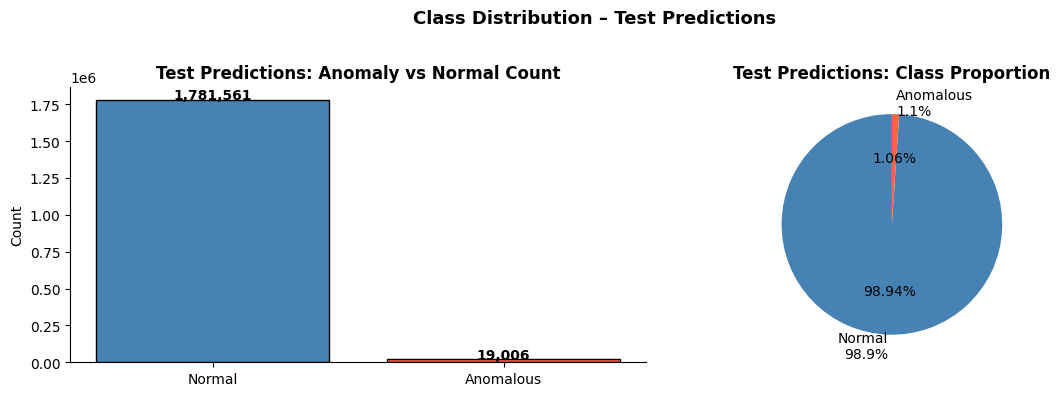

Normal predictions   : 1,781,561 (98.94%) 
Anomalous predictions: 19,006 (1.06%)


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate anomaly counts and percentages for test predictions
anomaly_counts_test = pd.Series(test_preds).value_counts().sort_index()
anomaly_pct_test = anomaly_counts_test / len(test_preds) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart for counts
axes[0].bar(['Normal', 'Anomalous'], anomaly_counts_test.values,
            color=['steelblue', 'tomato'], edgecolor='black')
axes[0].set_title('Test Predictions: Anomaly vs Normal Count', fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(anomaly_counts_test.values):
    axes[0].text(i, v + 5000, f'{v:,}', ha='center', fontweight='bold')

# Pie chart for proportions
axes[1].pie(anomaly_counts_test.values,
            labels=[f'Normal\n{anomaly_pct_test[0]:.1f}%', f'Anomalous\n{anomaly_pct_test[1]:.1f}%'],
            colors=['steelblue', 'tomato'], startangle=90, autopct='%1.2f%%')
axes[1].set_title('Test Predictions: Class Proportion', fontweight='bold')

plt.suptitle('Class Distribution – Test Predictions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Normal predictions   : {anomaly_counts_test[0]:,} ({anomaly_pct_test[0]:.2f}%) ")
print(f"Anomalous predictions: {anomaly_counts_test[1]:,} ({anomaly_pct_test[1]:.2f}%)")

<a id="sec13"></a>

## 13. Compare Anomaly Distribution: Train vs. Test

In [25]:
import pandas as pd

# Create a DataFrame to link test predictions with building IDs
test_predictions_df = pd.DataFrame({
    'building_id': test_fe['building_id'],
    'anomaly_prediction': test_preds
})

# Group by building_id and sum the anomaly predictions (where 1 indicates anomaly)
anomaly_counts_per_building = test_predictions_df.groupby('building_id')['anomaly_prediction'].sum()

# Sort in descending order to find buildings with the most anomalies
top_anomaly_buildings = anomaly_counts_per_building.sort_values(ascending=False)

print('Top 10 Building IDs with the Highest Number of Predicted Anomalies in Test Set:')
display(top_anomaly_buildings.head(10))

Top 10 Building IDs with the Highest Number of Predicted Anomalies in Test Set:


,anomaly_prediction
building_id,
984,342
956,323
738,320
943,272
963,261
927,248
878,239
724,235
127,232


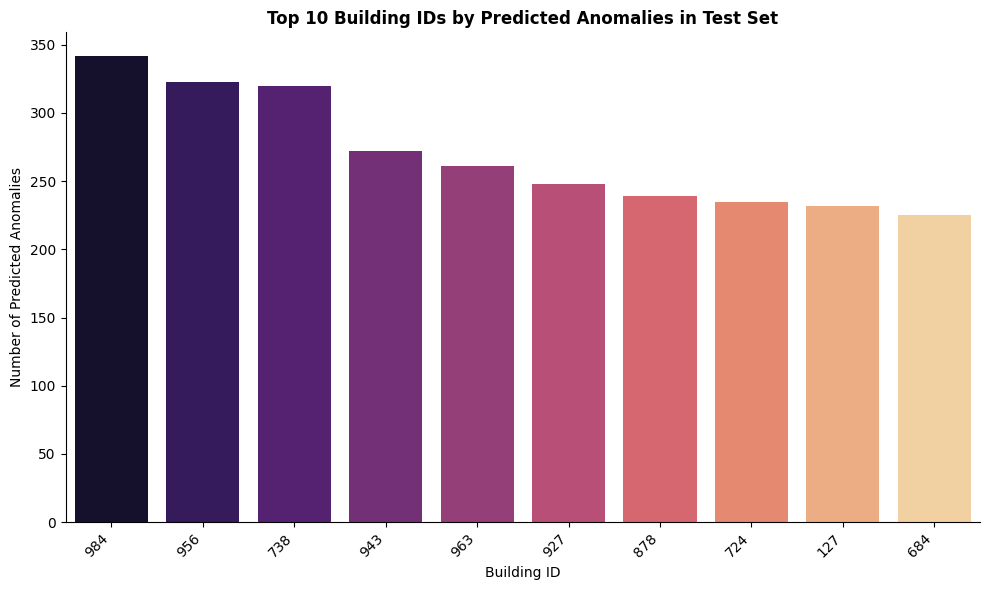

In [26]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_anomaly_buildings.head(10).index.astype(str),
            y=top_anomaly_buildings.head(10).values,
            palette='magma', ax=ax)
ax.set_title('Top 10 Building IDs by Predicted Anomalies in Test Set', fontweight='bold')
ax.set_xlabel('Building ID')
ax.set_ylabel('Number of Predicted Anomalies')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [27]:
# Get the building IDs of the top 10 anomaly buildings
top_10_anomaly_bld_ids = top_anomaly_buildings.head(10).index.tolist()

# Calculate building-level statistics for the test set
test_building_variability = (
    test.groupby('building_id')['meter_reading']
         .agg(
             observations='count',
             mean_reading='mean',
             median_reading='median',
             std_reading='std',
             min_reading='min',
             max_reading='max'
         )
)

# Coefficient of Variation (CV) for test buildings
test_building_variability['cv'] = (
    test_building_variability['std_reading'] /
    test_building_variability['mean_reading']
)

# Replace infinite values caused by mean = 0
test_building_variability['cv'] = (
    test_building_variability['cv']
    .replace([float('inf'), -float('inf')], pd.NA)
)

# Retrieve variability statistics for the top anomaly buildings from the TEST set variability
variability_of_top_anomaly_blds = test_building_variability.loc[top_10_anomaly_bld_ids]

print('Variability Statistics for Top 10 Building IDs with Highest Predicted Anomalies (from Test Data):')
display(variability_of_top_anomaly_blds[['mean_reading', 'std_reading', 'cv', 'min_reading', 'max_reading']])

Variability Statistics for Top 10 Building IDs with Highest Predicted Anomalies (from Test Data):


,mean_reading,std_reading,cv,min_reading,max_reading
building_id,,,,,
984,50.880390,14.480484,0.284599,1.0,73.000
956,49.377349,24.515046,0.496484,0.0,149.000
738,27.138862,26.443921,0.974393,1.0,123.500
943,4.167338,2.991099,0.717748,1.0,23.000
963,24.004734,8.619861,0.359090,1.0,51.000
927,828.965385,211.771757,0.255465,1.0,1974.000
878,33.067443,8.467004,0.256053,1.0,58.000
724,35.413562,37.260017,1.052140,1.0,169.800
127,21.150326,6.099655,0.288395,1.0,41.625


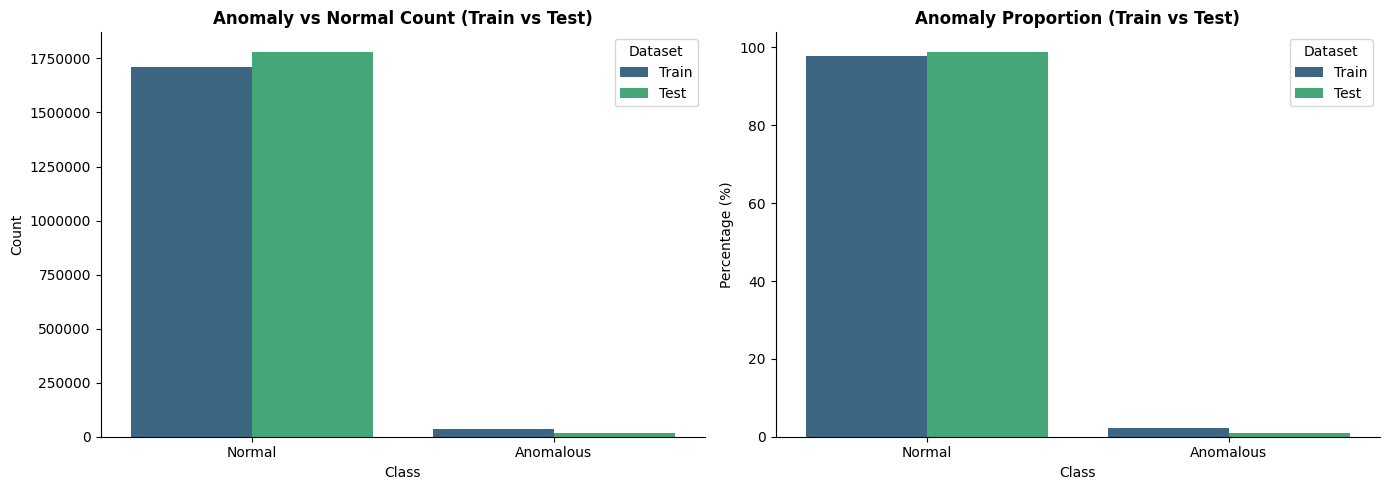


--- Anomaly Distribution Summary ---
Dataset     Class   Count  Percentage
  Train    Normal 1712198   97.868184
  Train Anomalous   37296    2.131816
   Test    Normal 1781561   98.944444
   Test Anomalous   19006    1.055556


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create DataFrames for comparison
# For training data (anomaly_counts, anomaly_pct already exist)
train_summary = pd.DataFrame({
    'Dataset': 'Train',
    'Class': ['Normal', 'Anomalous'],
    'Count': anomaly_counts.values,
    'Percentage': anomaly_pct.values
})

# For test data (anomaly_counts_test, anomaly_pct_test already exist)
test_summary = pd.DataFrame({
    'Dataset': 'Test',
    'Class': ['Normal', 'Anomalous'],
    'Count': anomaly_counts_test.values,
    'Percentage': anomaly_pct_test.values
})

# Concatenate for plotting
combined_summary = pd.concat([train_summary, test_summary])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart for counts
sns.barplot(x='Class', y='Count', hue='Dataset', data=combined_summary, palette='viridis', ax=axes[0])
axes[0].set_title('Anomaly vs Normal Count (Train vs Test)', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].ticklabel_format(style='plain', axis='y') # Prevent scientific notation on y-axis

# Bar chart for percentages
sns.barplot(x='Class', y='Percentage', hue='Dataset', data=combined_summary, palette='viridis', ax=axes[1])
axes[1].set_title('Anomaly Proportion (Train vs Test)', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')

plt.tight_layout()
plt.show()

print("\n--- Anomaly Distribution Summary ---")
print(combined_summary.to_string(index=False))

<a id="sec14"></a>

## 14. Point Anomaly Identification


 The cell below selects the 10 test-set rows with the **highest predicted anomaly probability** among those flagged by the final model, and attaches the engineered features (`z_score_24`, `pct_change_1`, `roll_mean_24`) that explain each flag in terms of the building's own recent behaviour — consistent with the exploratory finding (Section 3.2) that anomalies here are predominantly contextual rather than globally extreme (Chandola, Banerjee & Kumar, 2009).

In [34]:
# Identifies the 10 highest-confidence point anomalies in the test predictions
# and attaches the engineered features that explain each flag.

flagged_idx = np.where(test_preds == 1)[0]
flagged_probs = test_prob[flagged_idx]

# Rank flagged rows by model confidence (predicted probability), descending
order = np.argsort(-flagged_probs)
top10_idx = flagged_idx[order[:10]]

point_anomalies = test_fe.iloc[top10_idx][
    ['building_id', 'timestamp', 'meter_reading',
     'z_score_24', 'pct_change_1', 'roll_mean_24', 'roll_std_24']
].copy()
point_anomalies['predicted_probability'] = test_prob[top10_idx]

def explain_anomaly(row):
    """Rule-based, feature-grounded explanation for a single flagged reading."""
    reasons = []
    if abs(row['z_score_24']) >= 3:
        reasons.append(f"reading is {row['z_score_24']:.1f} standard deviations "
                       f"from its own 24h rolling mean (z-score)")
    if abs(row['pct_change_1']) >= 0.5:
        reasons.append(f"{row['pct_change_1']*100:.0f}% change vs. the previous "
                       f"hour (abrupt spike/drop)")
    if row['meter_reading'] <= 0.5 and row['roll_mean_24'] > 5:
        reasons.append("near-zero reading against an active recent baseline "
                       "(possible stuck/faulty meter)")
    if not reasons:
        reasons.append("reading deviates materially from the building's recent "
                       "rolling baseline (see z-score/roll_mean_24 columns)")
    return "; ".join(reasons)

point_anomalies['explanation'] = point_anomalies.apply(explain_anomaly, axis=1)
point_anomalies = point_anomalies.reset_index(drop=True)
point_anomalies.index += 1

print('10 Point Anomalies Identified in the Test Set (highest model confidence):')
display(point_anomalies[['building_id', 'timestamp', 'meter_reading',
                          'predicted_probability', 'z_score_24',
                          'pct_change_1', 'explanation']])


10 Point Anomalies Identified in the Test Set (highest model confidence):


,building_id,timestamp,meter_reading,predicted_probability,z_score_24,pct_change_1,explanation
1,983,2016-02-23 11:00:00,1.0,1.0,-4.451488,-0.997253,reading is -4.5 standard deviations from its o...
2,738,2016-01-09 09:00:00,1.0,1.0,-0.899697,0.000000,reading deviates materially from the building'...
3,738,2016-01-09 08:00:00,1.0,1.0,-0.978058,0.000000,reading deviates materially from the building'...
4,738,2016-01-09 07:00:00,1.0,1.0,-1.054446,0.000000,reading deviates materially from the building'...
5,736,2016-10-08 22:00:00,1.0,1.0,-0.344193,0.000000,reading deviates materially from the building'...
6,736,2016-10-08 21:00:00,1.0,1.0,-0.410226,0.000000,reading deviates materially from the building'...
7,736,2016-10-08 20:00:00,1.0,1.0,-0.474084,0.000000,reading deviates materially from the building'...
8,736,2016-10-08 19:00:00,1.0,1.0,-0.536607,0.000000,reading deviates materially from the building'...
9,736,2016-10-08 18:00:00,1.0,1.0,-0.598614,0.000000,reading deviates materially from the building'...
10,1299,2016-07-19 02:00:00,1.0,1.0,-1.510733,0.000000,reading deviates materially from the building'...


<a id="sec15"></a>

## 15. Submission File Creation

In [33]:
# Prepare submission DataFrame
submission = pd.DataFrame({
    'row_id': test['row_id'],
    'anomaly': test_preds
})

# Save submission file to the default Colab files directory
submission_path = '/content/submission.csv'
submission.to_csv(submission_path, index=False)

print(f'Submission file created and saved to: {submission_path}')
display(submission.head())

Submission file created and saved to: /content/submission.csv


,row_id,anomaly
0,0,0
206,206,0
411,411,0
617,617,0
823,823,0


<a id="sec16"></a>

## 16. References

Bergmeir, C. & Benítez, J.M. 2012. On the use of cross-validation for time series predictor evaluation. *Information Sciences*. 191:192-213.

Breiman, L. 2001. Random forests. *Machine Learning*. 45(1):5-32.

Chandola, V., Banerjee, A. & Kumar, V. 2009. Anomaly detection: a survey. *ACM Computing Surveys*. 41(3):1-58.

Chen, T. & Guestrin, C. 2016. XGBoost: a scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*. 13-17 August 2016. San Francisco: ACM. 785-794.

Davis, J. & Goadrich, M. 2006. The relationship between Precision-Recall and ROC curves. In *Proceedings of the 23rd International Conference on Machine Learning*. 25-29 June 2006. Pittsburgh: ACM. 233-240.

He, H. & Garcia, E.A. 2009. Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering*. 21(9):1263-1284.

Hyndman, R.J. & Athanasopoulos, G. 2021. *Forecasting: principles and practice*. 3rd ed. Melbourne: OTexts.

Lemaître, G., Nogueira, F. & Aridas, C.K. 2017. Imbalanced-learn: a Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research*. 18(17):1-5.

Little, R.J.A. & Rubin, D.B. 2019. *Statistical analysis with missing data*. 3rd ed. Hoboken, NJ: Wiley.

McKinney, W. 2010. Data structures for statistical computing in Python. In *Proceedings of the 9th Python in Science Conference*. 28 June - 3 July 2010. Austin: SciPy. 56-61.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M. & Duchesnay, E. 2011. Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*. 12:2825-2830.

Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A.V. & Gulin, A. 2018. CatBoost: unbiased boosting with categorical features. In *Advances in Neural Information Processing Systems 31*. 3-8 December 2018. Montreal: NeurIPS. 6638-6648.

Roberts, D.R., Bahn, V., Ciuti, S., Hardy, M.A., Hauenstein, S., Jung, M., Peters, J., Schroder, B., Muñoz, F., Warton, D.I. et al. 2017. Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*. 40(8):913-929.

Saito, T. & Rehmsmeier, M. 2015. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*. 10(3):e0118432.


